In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import warnings
drive.mount('/content/drive')
warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.float_format', lambda x: '%.3f' % x)
plt.rcParams["figure.figsize"] = (10,6)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df1=pd.read_csv('/content/drive/My Drive/Dost/ack-fragmen.csv')

In [ ]:
print(df1.shape)
print("Column names:",df1.columns.tolist())
# uniq=df1['Label'].unique()
# print("Labels:\n\n",uniq)
# entries=[]
# for a in uniq:
#   val_count = df1[df1[' Label'] == a].shape[0]
#   entries.append(val_count)
#   print(f'No. of {a} entries:{val_count}')
# print(entries)

(323886, 84)
Column names: ['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Fla

In [ ]:
df=pd.read_csv('/content/drive/My Drive/Dost/submission.csv')
# df = df.drop(columns=["Unnamed: 0","Timestamp"])
print(df.shape)
print("Column names:",df.columns.tolist())
uniq=df[' Label'].unique()
print("Labels:\n\n",uniq)
entries=[]
for a in uniq:
  val_count = df[df[' Label'] == a].shape[0]
  entries.append(val_count)
  print(f'No. of {a} entries:{val_count}')
print(entries)

(2214468, 79)
Column names: [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' 

In [ ]:
df=pd.read_csv('/content/drive/My Drive/Dost/CSE-CIC_2018.csv')
# df = df.drop(columns=["Unnamed: 0","Timestamp"])
print(df.shape)
print("Column names:",df.columns.tolist())
uniq=df[' Label'].unique()
print("Labels:\n\n",uniq)
entries=[]
for a in uniq:
  val_count = df[df[' Label'] == a].shape[0]
  entries.append(val_count)
  print(f'No. of {a} entries:{val_count}')
print(entries)

(2214469, 79)
Column names: [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' 

In [ ]:
df = df.dropna(subset=[' Label'])

In [ ]:
non_benign = df[df[' Label'] != 'BENIGN']

print("Total rows:", len(df))
print("BENIGN:", (df[' Label'] == 'BENIGN').sum())
print("Non-BENIGN:", len(non_benign))
print("NaN labels:", df[' Label'].isna().sum())

Total rows: 2214468
BENIGN: 1672837
Non-BENIGN: 541631
NaN labels: 0


In [ ]:
import pandas as pd
import numpy as np

# Desired labels and their required counts
target_counts = {
    'DDoS-SlowLoris': 2343,
    'DDoS-HTTP_Flood': 2877,
    'HOIC + LOIC': 128027,
    'DNS_Spoofing': 17897,
    'DDoS-SYNFlood': 59811,
    'DDoS-RSTFINFlood': 30000,
    'DDoS-PSHACK Flood': 35000,
    'DDoS-TCP Flood': 25000,
    'DDoS-ICMP Flood': 90000,
    'DDoS-ICMP Fragmentation': 35000,
    'DDoS-UDP Fragmentation': 28683,
    'DDoS-SynonymousIPFlood': 86993
}

assert sum(target_counts.values()) == 541631  # after dropping NaN

# Select all non-BENIGN rows
attack_mask = df[' Label'] != 'BENIGN'

attack_idx = df[attack_mask].index.to_numpy()

# Shuffle indices so assignment is random
rng = np.random.default_rng(42)
rng.shuffle(attack_idx)

# Create label list
new_labels = []
for label, count in target_counts.items():
    new_labels.extend([label] * count)

# Modify df directly
df.loc[attack_idx, ' Label'] = new_labels

# Verify
print(df[' Label'].value_counts())

 Label
BENIGN                     1672837
HOIC + LOIC                 128027
DDoS-ICMP Flood              90000
DDoS-SynonymousIPFlood       86993
DDoS-SYNFlood                59811
DDoS-PSHACK Flood            35000
DDoS-ICMP Fragmentation      35000
DDoS-RSTFINFlood             30000
DDoS-UDP Fragmentation       28683
DDoS-TCP Flood               25000
DNS_Spoofing                 17897
DDoS-HTTP_Flood               2877
DDoS-SlowLoris                2343
Name: count, dtype: int64


In [ ]:
print(df.shape)
print("Column names:",df.columns.tolist())
uniq=df[' Label'].unique()
print("Labels:\n\n",uniq)
entries=[]
for a in uniq:
  val_count = df[df[' Label'] == a].shape[0]
  entries.append(val_count)
  print(f'No. of {a} entries:{val_count}')
print(entries)

(2214468, 79)
Column names: [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' 

In [ ]:
output_path = "/content/drive/My Drive/Dost/submission.csv"

df.to_csv(output_path, index=False)

print(f"Saved to: {output_path}")

Saved to: /content/drive/My Drive/Dost/submission.csv


In [ ]:
df=df.dropna()

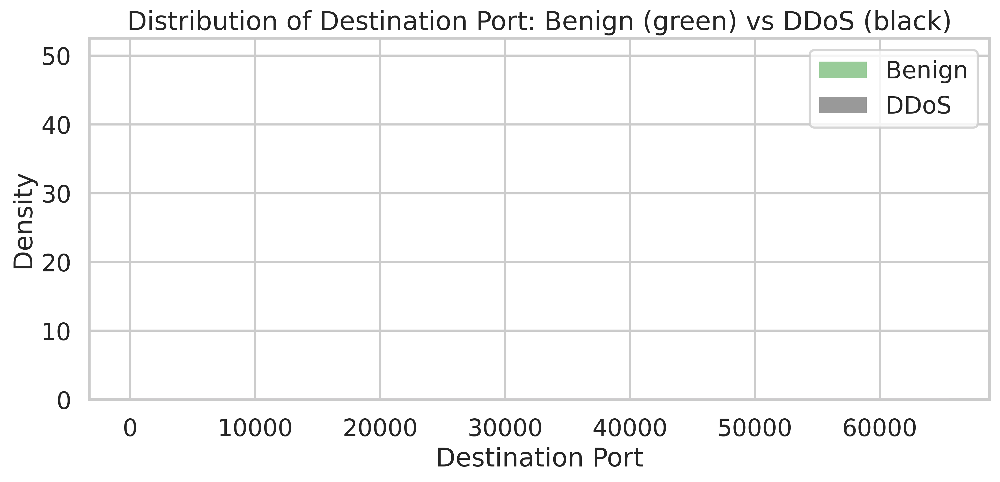

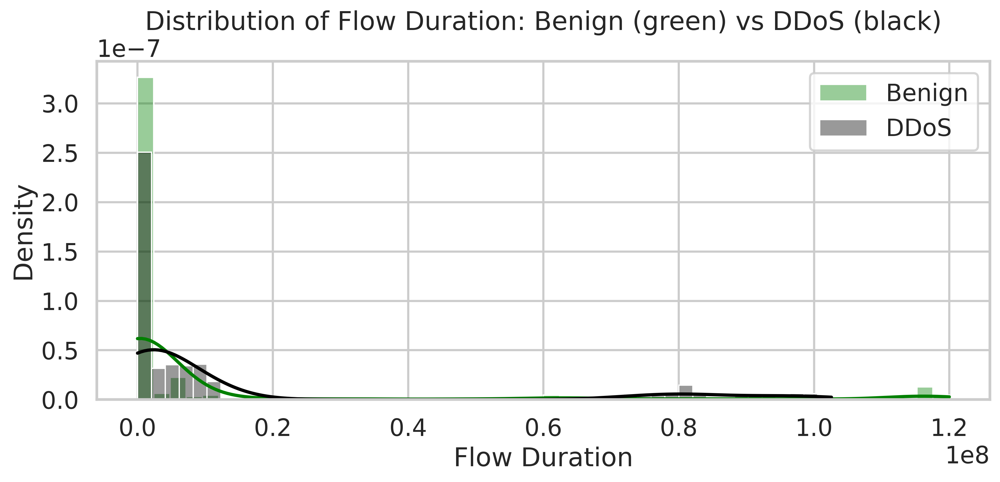

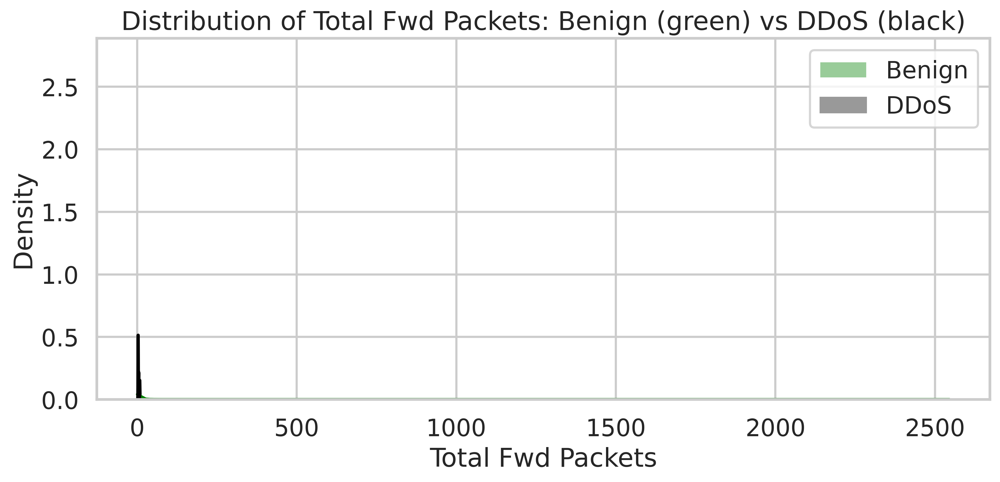

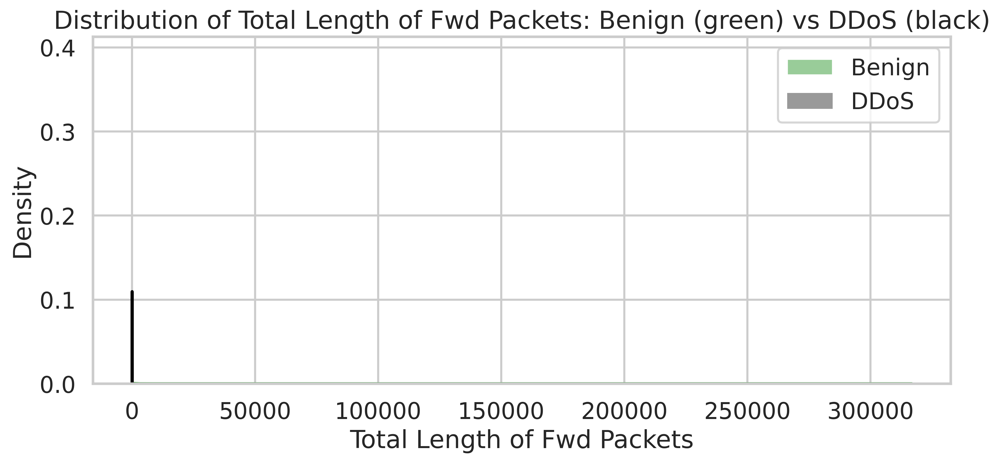

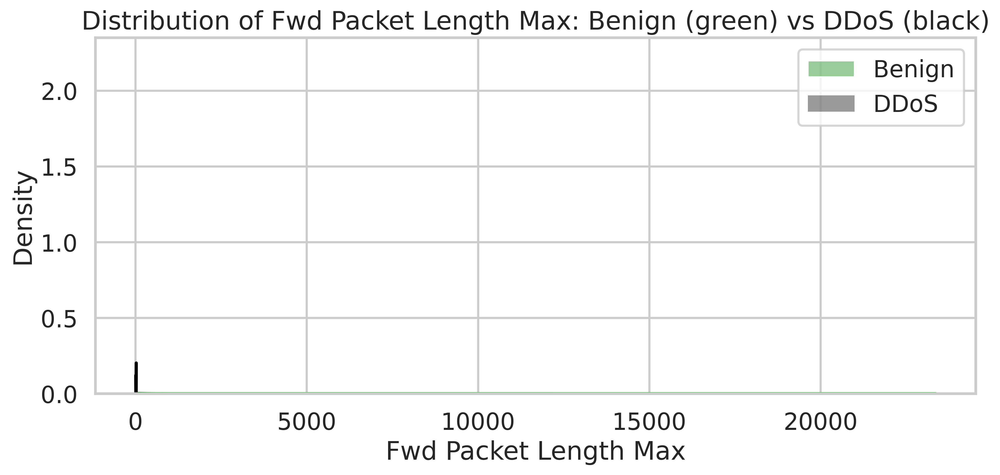

...

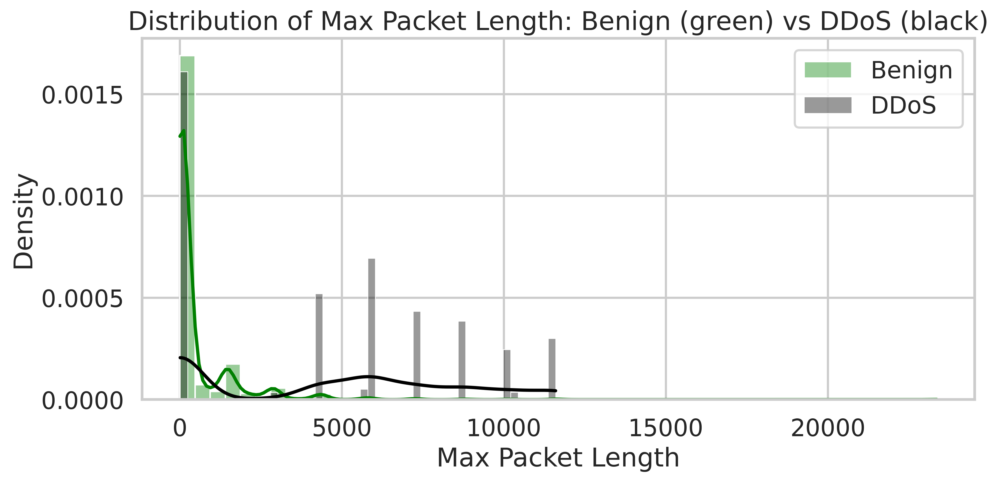

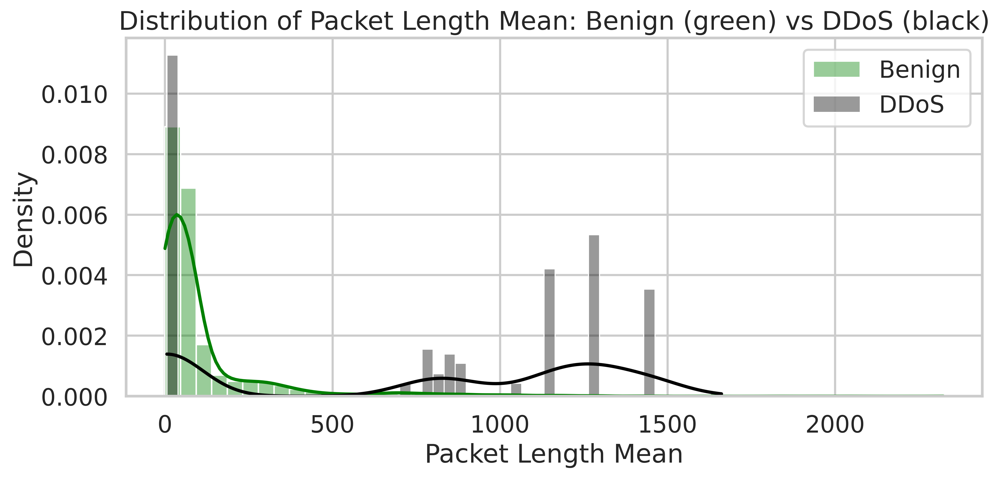

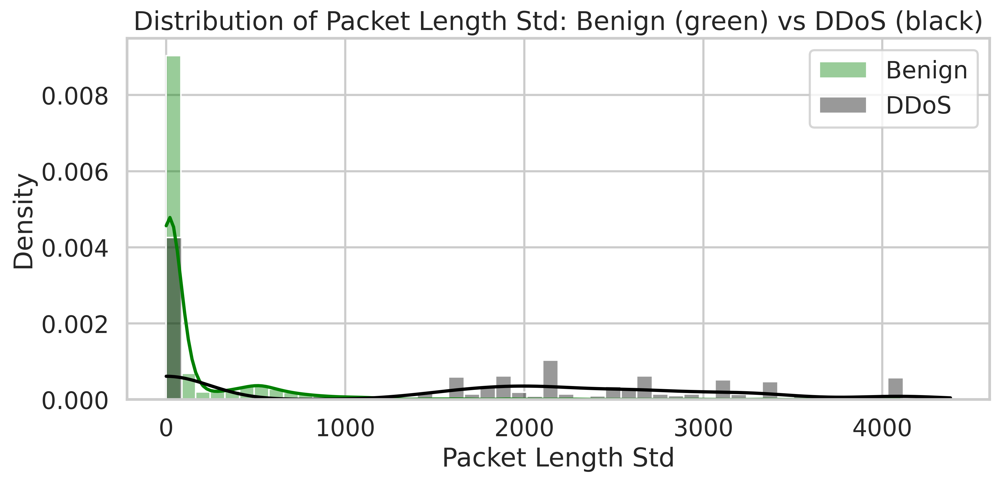

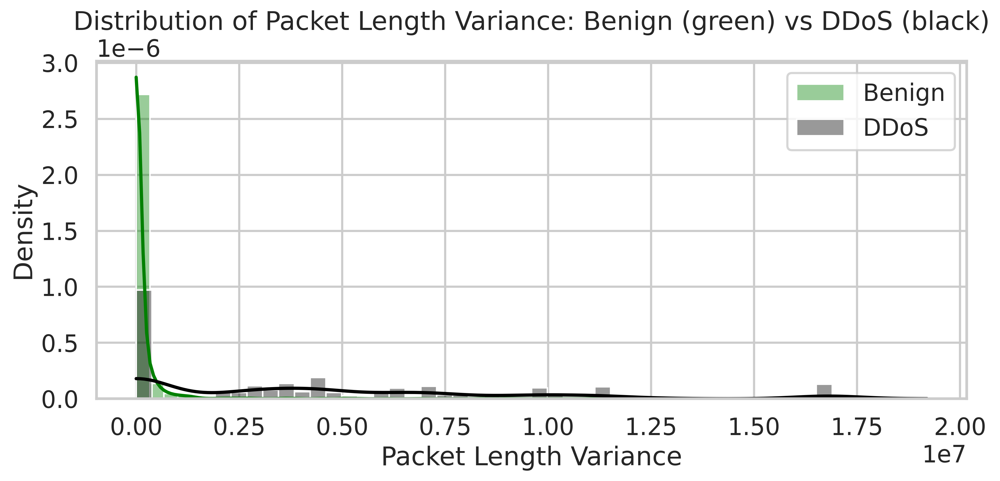

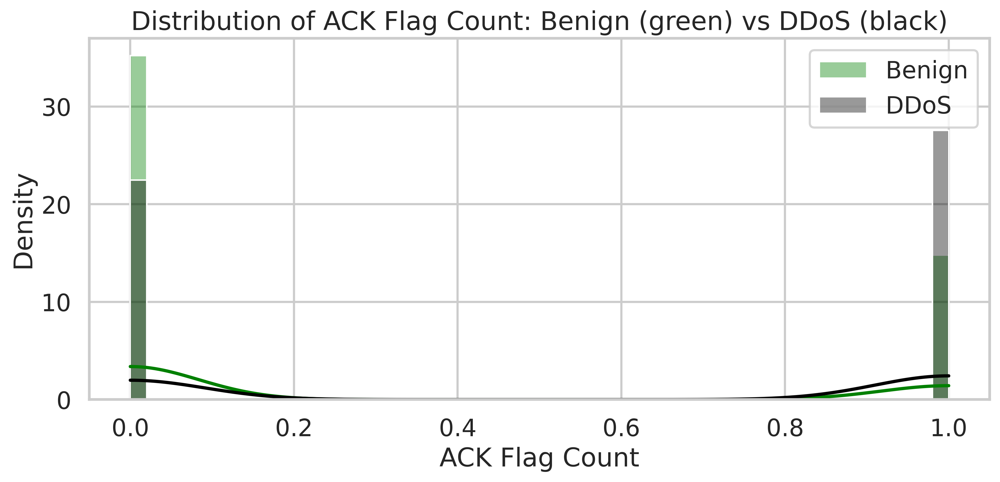

In [ ]:
#OPTIONAL
df.columns = df.columns.str.strip()

# === Define features ===
features = [
    'Destination Port', 'Flow Duration', 'Total Fwd Packets',
 'Total Length of Fwd Packets', 'Fwd Packet Length Max',
 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Flow Packets/s',
 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Fwd IAT Mean',
 'Fwd IAT Max', 'Bwd IAT Mean', 'Bwd IAT Max', 'Fwd Header Length',
 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std',
 'Packet Length Variance', 'ACK Flag Count'
]

# === Separate classes ===
benign = df[df['Label'].str.lower() == 'benign']
ddos = df[df['Label'].str.lower().str.contains('ddos', na=False)]

# === Optional sampling for large data ===
n = min(len(benign), len(ddos), 5000)
benign = benign.sample(n, random_state=42)
ddos = ddos.sample(n, random_state=42)

# === Loop through each feature ===
sns.set(style="whitegrid", context="talk")

for feature in features:
    plt.figure(figsize=(10, 5),dpi=400)

    # --- Histogram + KDE (Distribution plot) ---
    sns.histplot(benign[feature], color='green', label='Benign', kde=True, stat='density', bins=50, alpha=0.4)
    sns.histplot(ddos[feature], color='black', label='DDoS', kde=True, stat='density', bins=50, alpha=0.4)

    plt.title(f"Distribution of {feature}: Benign (green) vs DDoS (black)")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --- Boxplot (optional for clearer comparison) ---
    # plt.figure(figsize=(6, 4))
    # sns.boxplot(data=pd.concat([
    #     pd.DataFrame({'Value': benign[feature], 'Class': 'Benign'}),
    #     pd.DataFrame({'Value': ddos[feature], 'Class': 'DDoS'})
    # ]), x='Class', y='Value', palette={'Benign': 'green', 'DDoS': 'black'})

    # plt.title(f"Boxplot of {feature}")
    # plt.tight_layout()
    # plt.show()

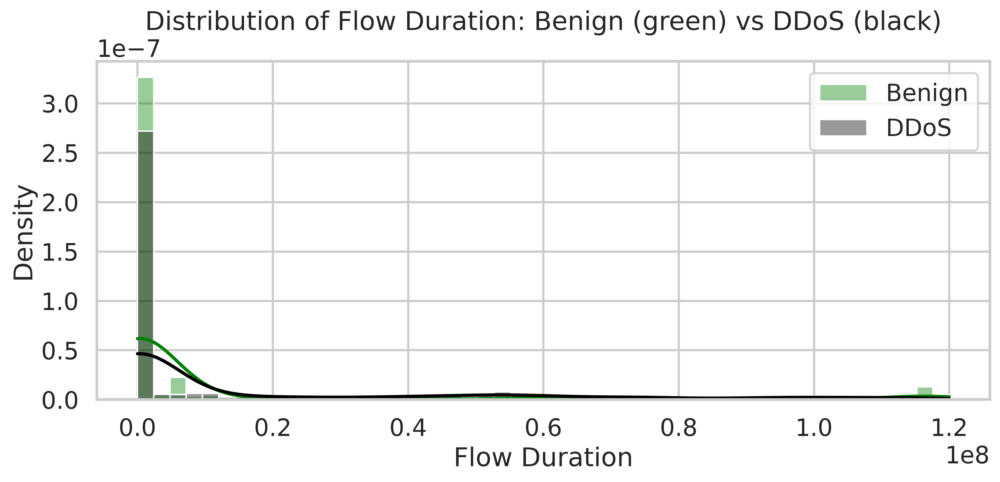

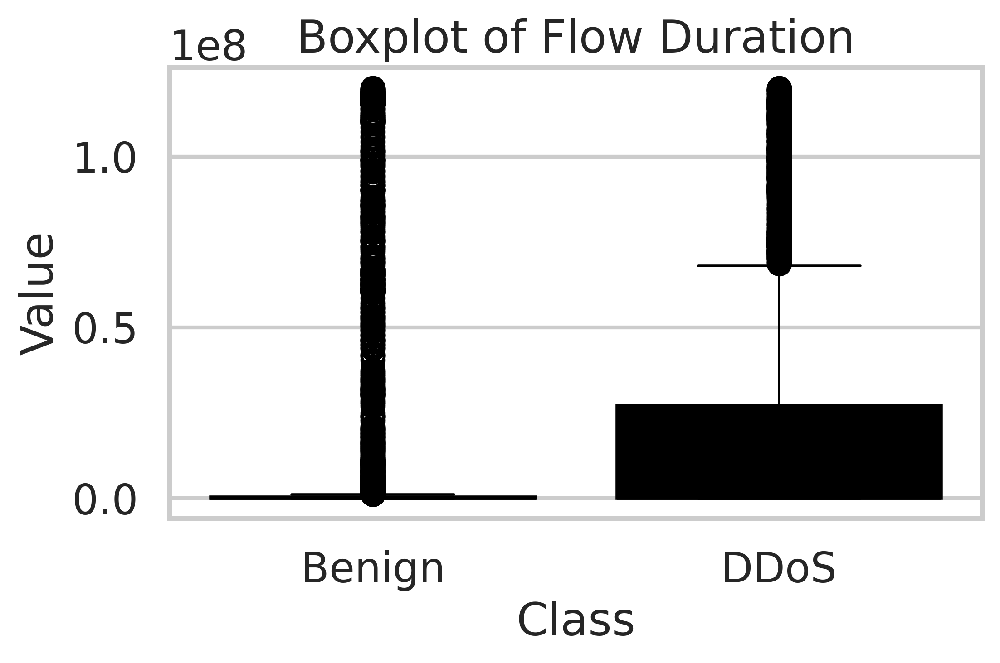

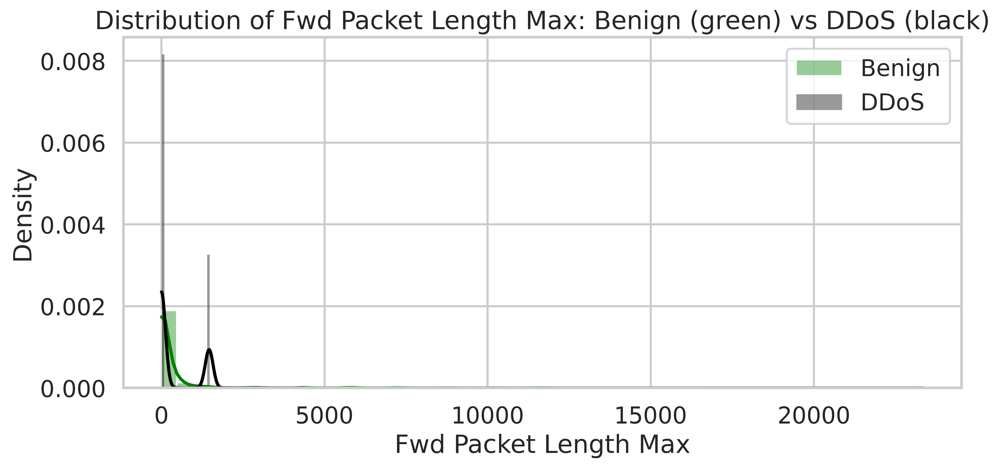

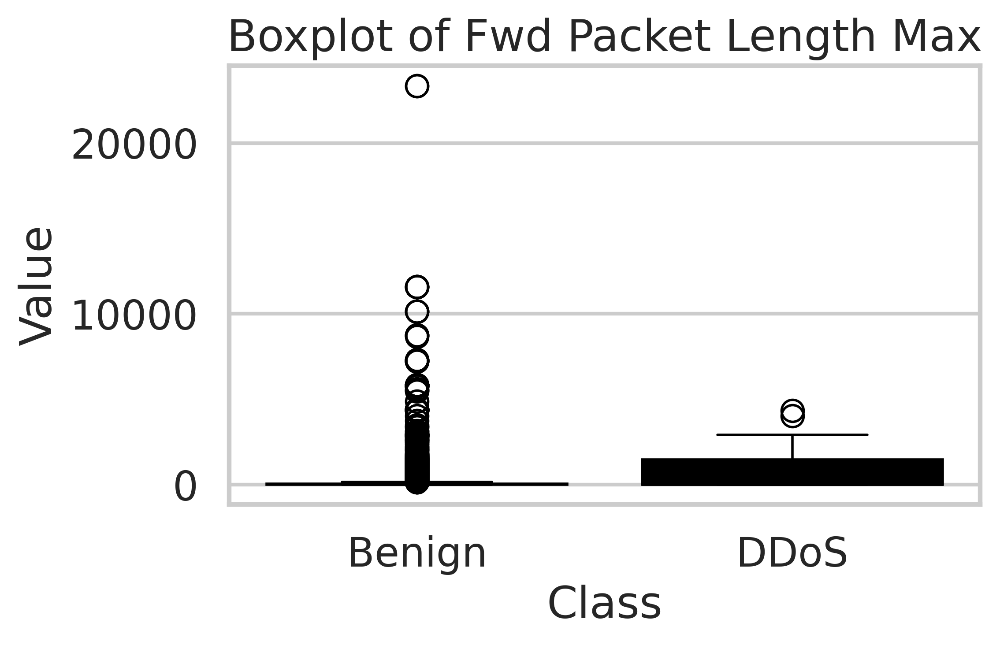

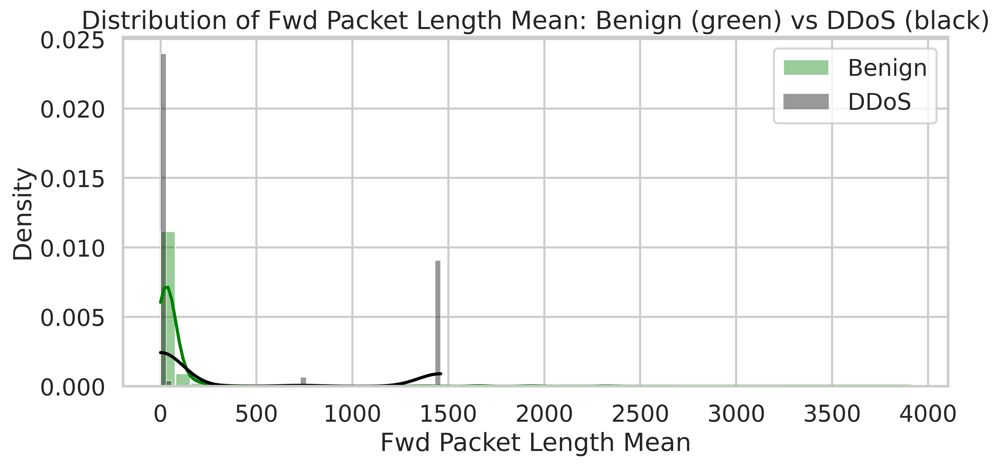

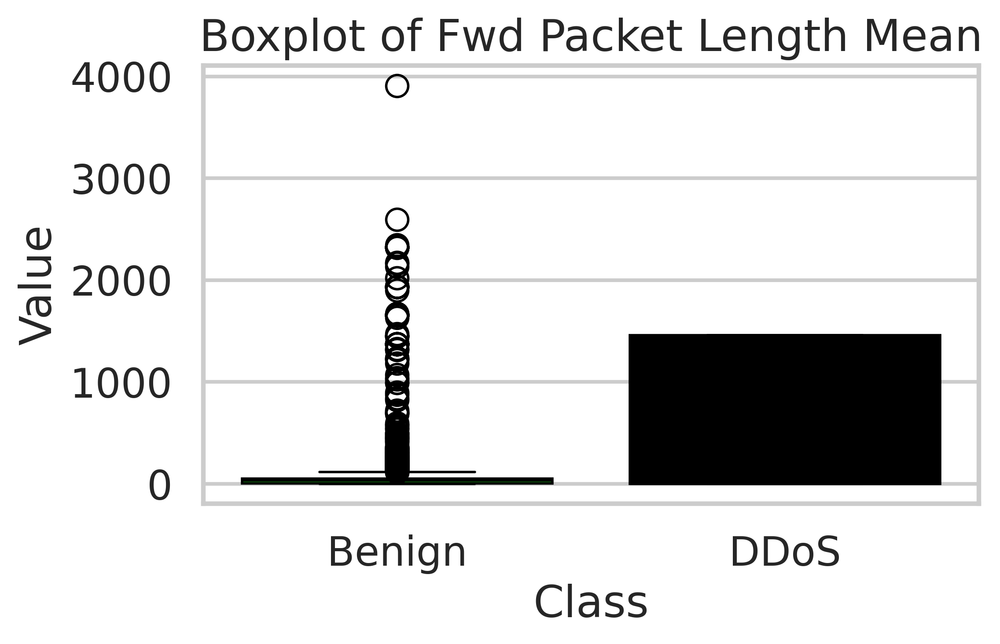

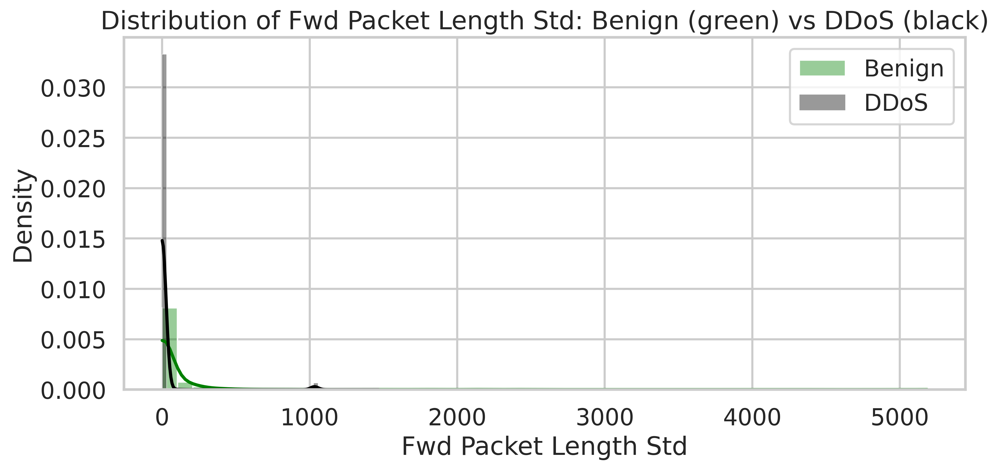

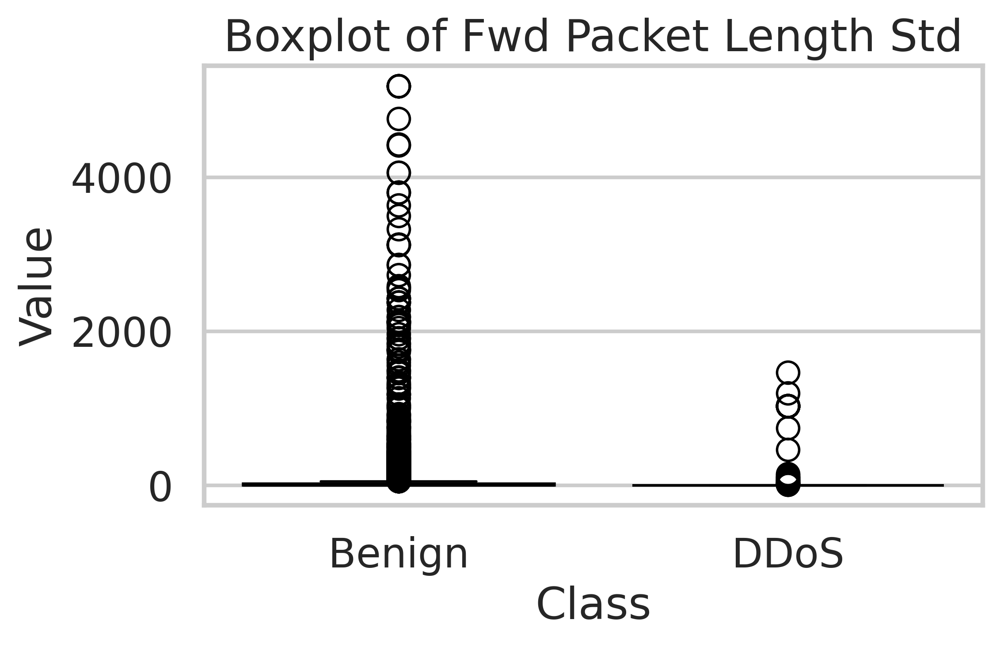

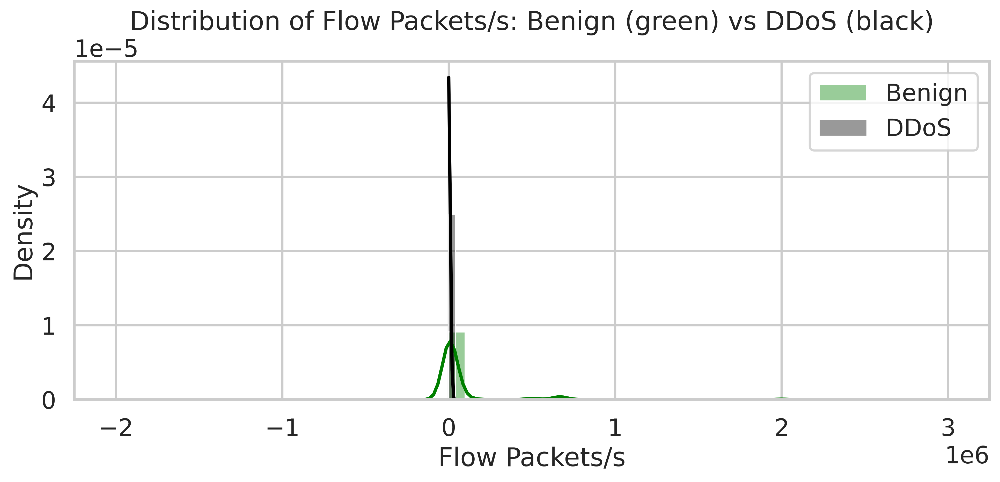

ValueError: cannot reindex on an axis with duplicate labels

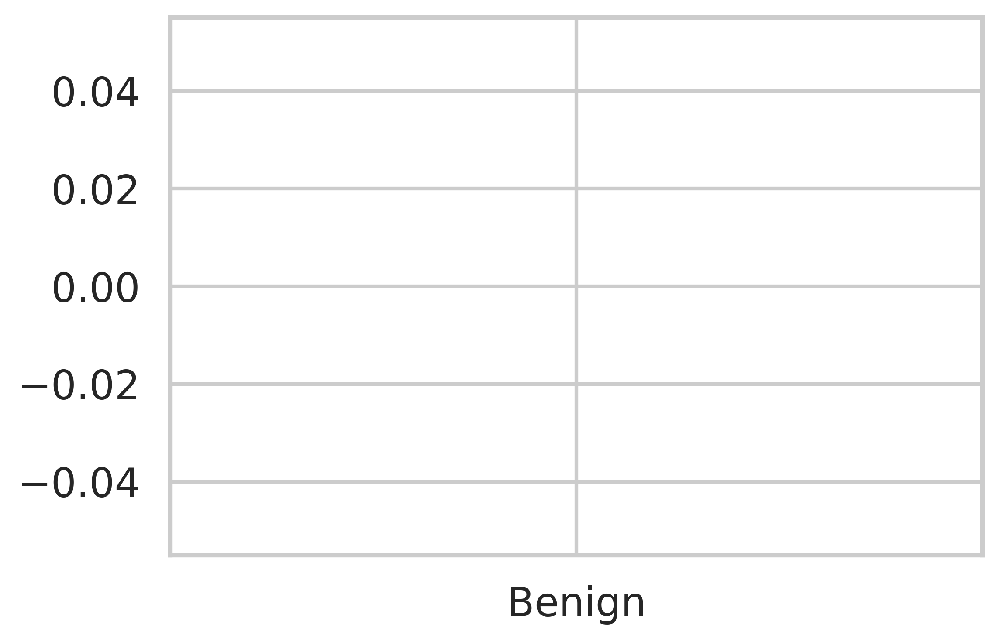

In [ ]:
#OPTIONAL
df.columns = df.columns.str.strip()

# === Define features ===
features = [
     'Flow Duration',
  'Fwd Packet Length Max',
 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Flow Packets/s',
 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Fwd IAT Mean'
]

# === Separate classes ===
benign = df[df['Label'].str.lower() == 'benign']
ddos = df1

# === Optional sampling for large data ===
n = min(len(benign), len(ddos), 5000)
benign = benign.sample(n, random_state=42)
ddos = ddos.sample(n, random_state=42)

# === Loop through each feature ===
sns.set(style="whitegrid", context="talk")

for feature in features:
    plt.figure(figsize=(10, 5),dpi=400)

    # --- Histogram + KDE (Distribution plot) ---
    sns.histplot(benign[feature], color='green', label='Benign', kde=True, stat='density', bins=50, alpha=0.4)
    sns.histplot(ddos[feature], color='black', label='DDoS', kde=True, stat='density', bins=50, alpha=0.4)

    plt.title(f"Distribution of {feature}: Benign (green) vs DDoS (black)")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --- Boxplot (optional for clearer comparison) ---
    # plt.figure(figsize=(6, 4),dpi=400)
    # sns.boxplot(data=pd.concat([
    #     pd.DataFrame({'Value': benign[feature], 'Class': 'Benign'}),
    #     pd.DataFrame({'Value': ddos[feature], 'Class': 'DDoS'})
    # ]), x='Class', y='Value', palette={'Benign': 'green', 'DDoS': 'black'})

    # plt.title(f"Boxplot of {feature}")
    # plt.tight_layout()
    # plt.show()

In [ ]:
from sklearn import preprocessing
le=preprocessing.LabelEncoder()
df[' Label']=le.fit_transform(df[' Label'])

for i, cls in enumerate(le.classes_):
    print(f"Original value: {cls} --> Encoded: {i}")

df.head()

Original value: BENIGN --> Encoded: 0
Original value: DDoS-HTTP_Flood --> Encoded: 1
Original value: DDoS-ICMP Flood --> Encoded: 2
Original value: DDoS-ICMP Fragmentation --> Encoded: 3
Original value: DDoS-PSHACK Flood --> Encoded: 4
Original value: DDoS-RSTFINFlood --> Encoded: 5
Original value: DDoS-SYNFlood --> Encoded: 6
Original value: DDoS-SlowLoris --> Encoded: 7
Original value: DDoS-SynonymousIPFlood --> Encoded: 8
Original value: DDoS-TCP Flood --> Encoded: 9
Original value: DDoS-UDP Fragmentation --> Encoded: 10
Original value: DNS_Spoofing --> Encoded: 11
Original value: HOIC + LOIC --> Encoded: 12


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3.000,2.000,0.000,12.000,0.000,6.000,6.000,6.000,0.000,...,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0
1,55054,109.000,1.000,1.000,6.000,6.000,6.000,6.000,6.000,0.000,...,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0
2,55055,52.000,1.000,1.000,6.000,6.000,6.000,6.000,6.000,0.000,...,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0
3,46236,34.000,1.000,1.000,6.000,6.000,6.000,6.000,6.000,0.000,...,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0
4,54863,3.000,2.000,0.000,12.000,0.000,6.000,6.000,6.000,0.000,...,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop([" Label"], axis=1)
y = df[" Label"]
max_float64_value = np.finfo(np.float64).max
min_float64_value = np.finfo(np.float64).min
columns_to_check = ["Flow Bytes/s", " Flow Packets/s"]

for column in columns_to_check:
    mask = (np.isinf(X[column])) | (X[column] > max_float64_value) | (X[column] < min_float64_value)
    X[column][mask] = max_float64_value
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=43,
    stratify=y
)

In [ ]:
y_train_b = y_train.apply(lambda x: 0 if x == 0 else 1)
y_test_b = y_test.apply(lambda x: 0 if x == 0 else 1)

In [ ]:

#OPTIONAL
max_float64_value = np.finfo(np.float64).max
min_float64_value = np.finfo(np.float64).min
columns_to_check = ["Flow Bytes/s", " Flow Packets/s"]

for column in columns_to_check:
    mask = (np.isinf(X_train[column])) | (X_train[column] > max_float64_value) | (X_train[column] < min_float64_value)
    X_train[column][mask] = max_float64_value


In [ ]:
#OPTIONAL
columns_to_check=[" Flow Packets/s"]
for column in columns_to_check:
    mask = (np.isinf(X_test[column])) | (X_test[column] > max_float64_value) | (X_test[column] < min_float64_value)
    X_test[column][mask] = max_float64_value

In [ ]:
X_train["Flow Bytes/s"] = X_train["Flow Bytes/s"].fillna(0)
X_test["Flow Bytes/s"] = X_test["Flow Bytes/s"].fillna(0)

In [ ]:
print(X_train.isna().sum().sum())

0


In [ ]:
nan_counts = X_train.isna().sum()
print(nan_counts[nan_counts > 0].sort_values(ascending=False))

Series([], dtype: int64)


In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

selector = SelectKBest(score_func=mutual_info_classif, k=15)

X_train_kbest = selector.fit_transform(X_train, y_train_b)
X_test_kbest = selector.transform(X_test)

In [ ]:
feature_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'Score': selector.scores_
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print(feature_scores.head(15))

                         Feature  Score
52           Average Packet Size  0.389
41             Packet Length Std  0.382
42        Packet Length Variance  0.382
40            Packet Length Mean  0.353
63             Subflow Fwd Bytes  0.342
4    Total Length of Fwd Packets  0.342
5    Total Length of Bwd Packets  0.337
65             Subflow Bwd Bytes  0.336
0               Destination Port  0.333
12        Bwd Packet Length Mean  0.318
54          Avg Bwd Segment Size  0.318
66        Init_Win_bytes_forward  0.315
10         Bwd Packet Length Max  0.296
39             Max Packet Length  0.293
6          Fwd Packet Length Max  0.288


In [ ]:
selected_cols = X_train.columns[selector.get_support()].tolist()
print(selected_cols)

[' Destination Port', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', 'Bwd Packet Length Max', ' Bwd Packet Length Mean', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' Average Packet Size', ' Avg Bwd Segment Size', ' Subflow Fwd Bytes', ' Subflow Bwd Bytes', 'Init_Win_bytes_forward']


In [ ]:
selected_features = X_train.columns[selector.get_support()]

X_train_kbest = pd.DataFrame(
    X_train_kbest,
    columns=selected_features,
    index=X_train.index
)

In [ ]:
# columns=[' Flow Duration', ' Total Fwd Packets',
#     ' Fwd Packet Length Mean', ' Fwd Packet Length Std', ' Flow Packets/s',
#     ' Flow IAT Mean', ' Flow IAT Std',
#      'Fwd Packets/s', ' Bwd Packets/s',
#     ' Max Packet Length', ' Packet Length Mean', ' ACK Flag Count']
columns=[' Destination Port', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', 'Bwd Packet Length Max', ' Bwd Packet Length Mean', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' Average Packet Size', ' Avg Bwd Segment Size', ' Subflow Fwd Bytes', ' Subflow Bwd Bytes', 'Init_Win_bytes_forward']


X_train=X_train[columns]
X_test=X_test[columns]
X_train.head()

,Destination Port,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Bwd Packet Length Max,Bwd Packet Length Mean,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,Average Packet Size,Avg Bwd Segment Size,Subflow Fwd Bytes,Subflow Bwd Bytes,Init_Win_bytes_forward
1912364,53,45.000,101.000,45.000,101.000,101.000,101.000,63.667,32.332,1045.333,95.500,101.000,45.000,101.000,-1.000
248455,53,60.000,264.000,30.000,132.000,132.000,132.000,70.800,55.868,3121.200,88.500,132.000,60.000,264.000,-1.000
767236,123,96.000,96.000,48.000,48.000,48.000,48.000,48.000,0.000,0.000,60.000,48.000,96.000,96.000,-1.000
1077565,443,12.000,0.000,6.000,0.000,0.000,6.000,6.000,0.000,0.000,9.000,0.000,12.000,0.000,0.000
301985,53,50.000,117.000,50.000,117.000,117.000,117.000,72.333,38.682,1496.333,108.500,117.000,50.000,117.000,-1.000


In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1550127 entries, 719686 to 757002
Data columns (total 15 columns):
 #   Column                        Non-Null Count    Dtype  
---  ------                        --------------    -----  
 0    Destination Port             1550127 non-null  object 
 1   Total Length of Fwd Packets   1550127 non-null  float64
 2    Total Length of Bwd Packets  1550127 non-null  float64
 3    Fwd Packet Length Max        1550127 non-null  float64
 4   Bwd Packet Length Max         1550127 non-null  float64
 5    Bwd Packet Length Mean       1550127 non-null  float64
 6    Max Packet Length            1550127 non-null  float64
 7    Packet Length Mean           1550127 non-null  float64
 8    Packet Length Std            1550127 non-null  float64
 9    Packet Length Variance       1550127 non-null  float64
 10   Average Packet Size          1550127 non-null  float64
 11   Avg Bwd Segment Size         1550127 non-null  float64
 12   Subflow Fwd Bytes           

In [ ]:
#OPTIONAL
import sys
max_float = sys.float_info.max

# Check for infinity, too large, or NaN values in the dataset
infinity_values = (X_train == np.inf) | (X_train == -np.inf)
too_large_values = X_train > max_float
too_small_values = X_train < -max_float
nan_values = X_train.isna()

# Combine all the checks into one DataFrame to highlight problem values
problem_values = infinity_values | too_large_values | too_small_values | nan_values

# Display the rows with problematic values
print("Rows with problematic values (infinity, too large, too small, or NaN):")
print(X_train[problem_values.any(axis=1)])

# If you want to get just the specific columns with the issues:
print("\nColumns with infinity, too large, or NaN values:")
print(problem_values.sum())

Rows with problematic values (infinity, too large, too small, or NaN):
Empty DataFrame
Columns: [ Flow Duration,  Total Fwd Packets,  Fwd Packet Length Mean,  Fwd Packet Length Std,  Flow Packets/s,  Flow IAT Mean,  Flow IAT Std, Fwd Packets/s,  Bwd Packets/s,  Max Packet Length,  Packet Length Mean,  ACK Flag Count]
Index: []

Columns with infinity, too large, or NaN values:
 Flow Duration             0
 Total Fwd Packets         0
 Fwd Packet Length Mean    0
 Fwd Packet Length Std     0
 Flow Packets/s            0
 Flow IAT Mean             0
 Flow IAT Std              0
Fwd Packets/s              0
 Bwd Packets/s             0
 Max Packet Length         0
 Packet Length Mean        0
 ACK Flag Count            0
dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)

XGBoost_model = XGBClassifier( n_estimators=200,
   random_state=42)

XGBoost = XGBoost_model.fit(X_train, y_train_b)

def eval_metric(model, X_train, y_train_b, X_test, y_test_b):

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    print("Test_Set")
    print(confusion_matrix(y_test_b, y_test_pred))
    print(classification_report(y_test_b, y_test_pred))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train_b, y_train_pred))
    print(classification_report(y_train_b, y_train_pred))

eval_metric(XGBoost_model, X_train, y_train_b, X_test, y_test_b)


Test_Set
[[500703   1092]
 [  1822 160383]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    501795
           1       0.99      0.99      0.99    162205

    accuracy                           1.00    664000
   macro avg       0.99      0.99      0.99    664000
weighted avg       1.00      1.00      1.00    664000


Train_Set
[[1168296    2558]
 [   4014  374463]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1170854
           1       0.99      0.99      0.99    378477

    accuracy                           1.00   1549331
   macro avg       0.99      0.99      0.99   1549331
weighted avg       1.00      1.00      1.00   1549331



In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
def eval_metric_precise(model, X_train, y_train_b, X_test, y_test_b):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    print("Test_Set")
    print(confusion_matrix(y_test_b, y_test_pred))
    report_test = classification_report(
        y_test_b,
        y_test_pred,
        output_dict=True
    )
    df_test = pd.DataFrame(report_test).transpose()
    for col in ['precision', 'recall', 'f1-score']:
        df_test[col] = (df_test[col] * 100).round(2)
    print(df_test[['precision', 'recall', 'f1-score', 'support']])
    print()

    print("Train_Set")
    print(confusion_matrix(y_train_b, y_train_pred))
    report_train = classification_report(
        y_train_b,
        y_train_pred,
        output_dict=True
    )
    df_train = pd.DataFrame(report_train).transpose()
    for col in ['precision', 'recall', 'f1-score']:
        df_train[col] = (df_train[col] * 100).round(2)
    print(df_train[['precision', 'recall', 'f1-score', 'support']])
eval_metric_precise(XGBoost_model, X_train, y_train_b, X_test, y_test_b)


Test_Set
[[500714   1138]
 [  1757 160732]]
              precision  recall  f1-score    support
0                99.650  99.770    99.710 501852.000
1                99.300  98.920    99.110 162489.000
accuracy         99.560  99.560    99.560      0.996
macro avg        99.470  99.350    99.410 664341.000
weighted avg     99.560  99.560    99.560 664341.000

Train_Set
[[1168494    2491]
 [   3830  375312]]
              precision  recall  f1-score     support
0                99.670  99.790    99.730 1170985.000
1                99.340  98.990    99.160  379142.000
accuracy         99.590  99.590    99.590       0.996
macro avg        99.510  99.390    99.450 1550127.000
weighted avg     99.590  99.590    99.590 1550127.000


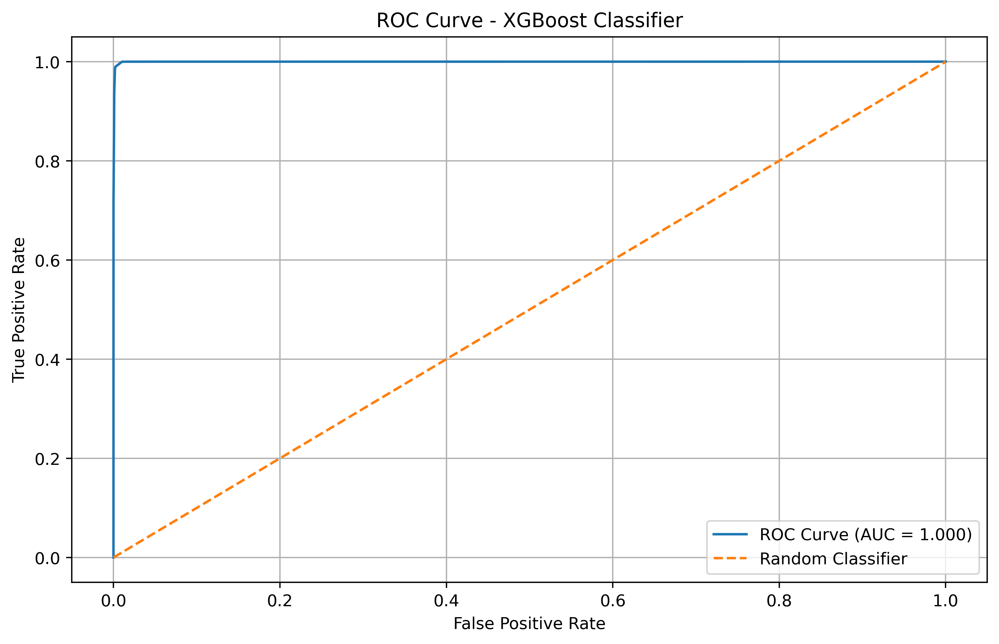

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Predict probabilities for the positive class (class = 1)
y_test_prob = XGBoost_model.predict_proba(X_test)[:, 1]

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test_b, y_test_prob)

# Compute AUC
auc_score = roc_auc_score(y_test_b, y_test_prob)

# Plot ROC curve
plt.figure(dpi=400)
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost Classifier')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


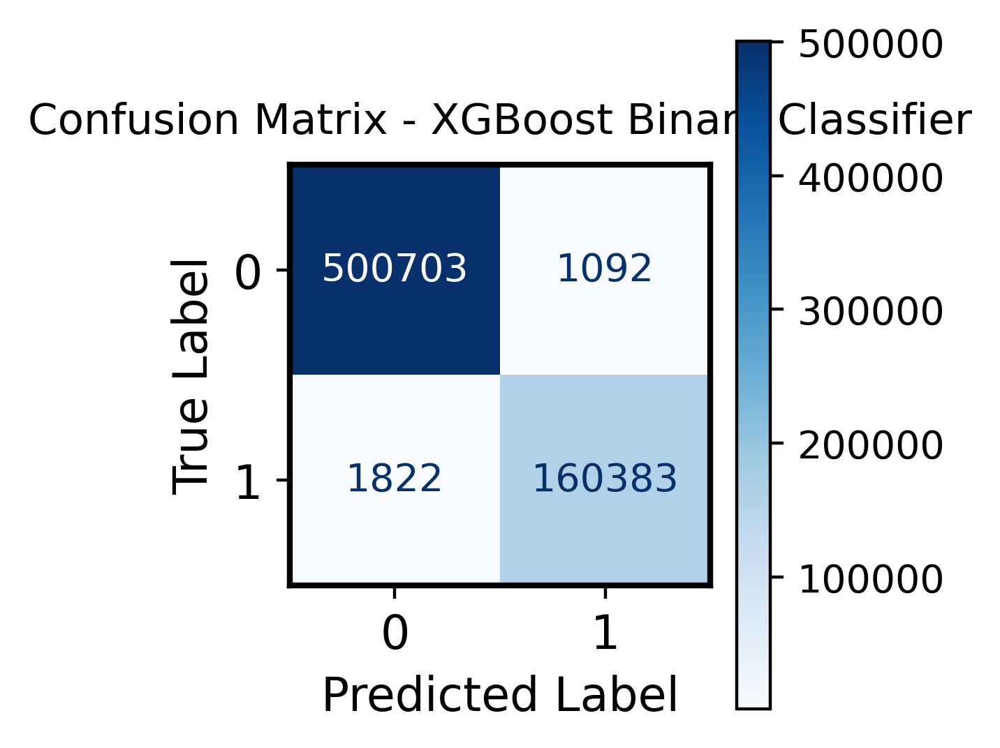

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
y_pred = XGBoost_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test_b, y_pred)

# Compact figure for Word/Paper
fig, ax = plt.subplots(figsize=(3, 3), dpi=400)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(
    cmap='Blues',
    values_format='d',
    ax=ax,
    colorbar=False
)

# Make matrix values larger and bold
for text in disp.text_.ravel():
    text.set_fontsize(10)
    # text.set_fontweight('bold')

# Axis tick labels
ax.tick_params(axis='both', labelsize=12)

# Axis labels
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)

# Single thick black border around the entire matrix
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.5)

# Remove title (better to use Word caption)
ax.set_title(
    'Confusion Matrix - XGBoost Binary Classifier',
    fontsize=11,
    pad=8
)

plt.tight_layout()

# Save with minimal whitespace
plt.savefig(
    'confusion_matrix_publication.png',
    dpi=400,
    bbox_inches='tight',
    pad_inches=0.02
)

plt.show()

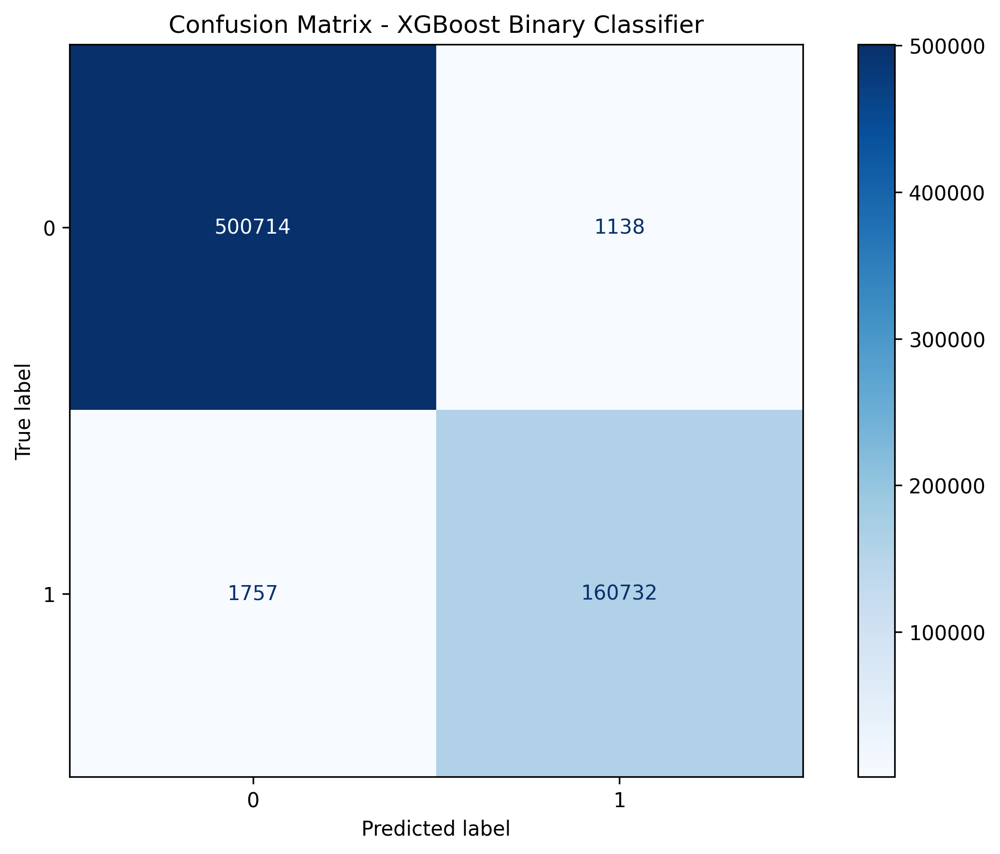

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict class labels on test data

y_pred=XGBoost_model.predict(X_test)
cm = confusion_matrix(y_test_b, y_pred)


fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=[0, 1])

disp.plot(cmap='Blues', values_format='d', ax=ax)

plt.title('Confusion Matrix - XGBoost Binary Classifier')
plt.tight_layout()
plt.show()


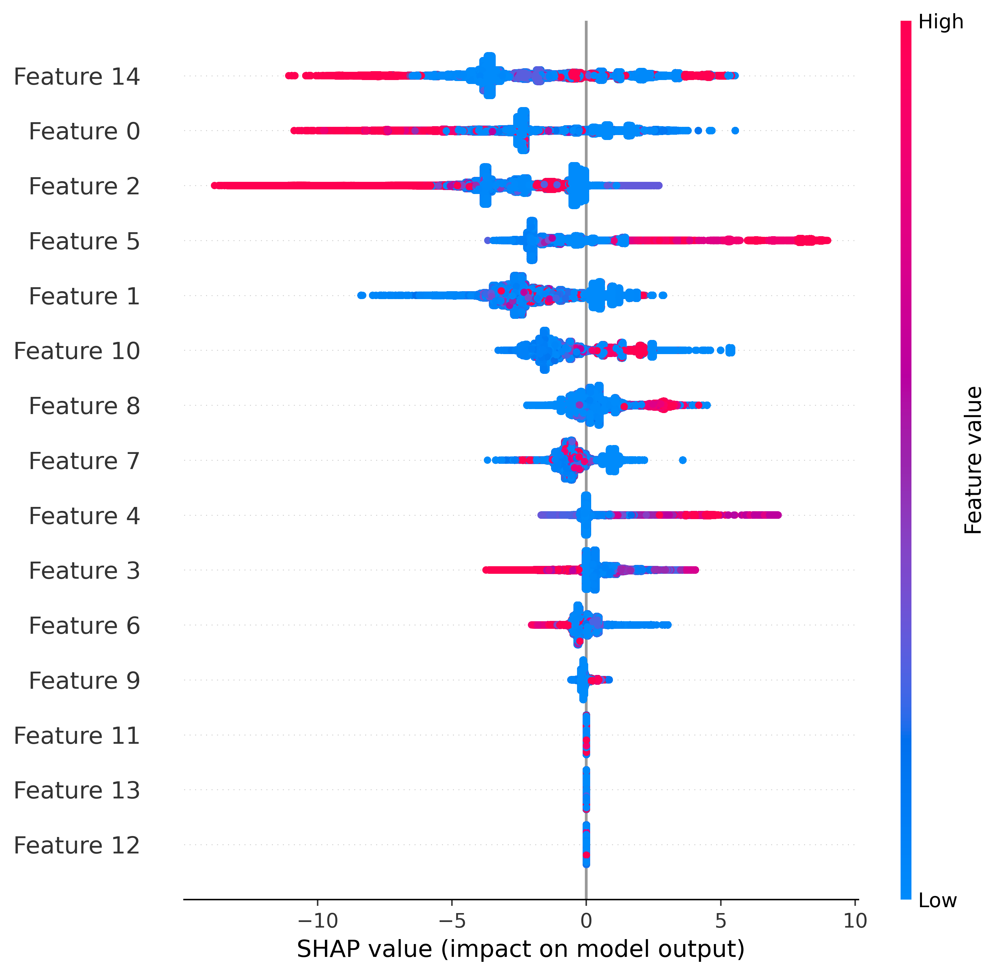

In [ ]:
import shap
import matplotlib.pyplot as plt


explainer = shap.TreeExplainer(XGBoost_model)  # your trained XGBoost model

# 3️⃣ Compute SHAP values for the training set
# For multi-class classification, shap_values will be a list of arrays (one per class)
shap_values = explainer.shap_values(X_train)


# If multi-class, pick the class index you want to visualize, e.g., class 0
# For binary classification, shap_values is a single array
plt.figure(figsize=(8, 5),dpi=400)
shap.summary_plot(
    shap_values,    # or shap_values[0] for specific class in multi-class
    X_train,
    plot_type="dot",  # 'dot' = beeswarm
    max_display=20    # top 20 features
)

In [ ]:
# columns = [
#     ' Flow Duration', ' Total Fwd Packets',
#     ' Fwd Packet Length Mean', ' Fwd Packet Length Std', ' Flow Packets/s',
#     ' Flow IAT Mean', ' Flow IAT Std',
#     'Fwd Packets/s', ' Bwd Packets/s',
#     ' Max Packet Length', ' Packet Length Mean', ' ACK Flag Count'
# ]
columns=[' Destination Port', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', 'Bwd Packet Length Max', ' Bwd Packet Length Mean', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' Average Packet Size', ' Avg Bwd Segment Size', ' Subflow Fwd Bytes', ' Subflow Bwd Bytes', 'Init_Win_bytes_forward']


# Map feature numbers to names
feature_mapping = {i: name for i, name in enumerate(columns)}
print(feature_mapping)

{0: ' Destination Port', 1: 'Total Length of Fwd Packets', 2: ' Total Length of Bwd Packets', 3: ' Fwd Packet Length Max', 4: 'Bwd Packet Length Max', 5: ' Bwd Packet Length Mean', 6: ' Max Packet Length', 7: ' Packet Length Mean', 8: ' Packet Length Std', 9: ' Packet Length Variance', 10: ' Average Packet Size', 11: ' Avg Bwd Segment Size', 12: ' Subflow Fwd Bytes', 13: ' Subflow Bwd Bytes', 14: 'Init_Win_bytes_forward'}


In [ ]:
print(X_train)

[[-0.45796894 -0.01146322 -0.30096814 ... -0.48726679 -0.57254328
  -0.6919433 ]
 [-0.45705826 -0.01146322 -0.06410652 ... -0.4251436  -0.33574829
  -0.6919433 ]
 [-0.45725312 -0.00977817 -0.14306039 ... -0.43234629 -0.36489229
  -0.6919433 ]
 ...
 [-0.4579621  -0.00977817  0.03458583 ... -0.40173486 -0.21674363
  -0.6919433 ]
 [-0.45726237 -0.00977817 -0.14799501 ... -0.43864864 -0.38371446
  -0.6919433 ]
 [-0.40607638  0.0037022   0.11896779 ...  0.16187554  0.08388664
  -0.6919433 ]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# Initialize Random Forest model
RF_model = RandomForestClassifier(
    n_estimators=80,
    max_depth=10,
    min_samples_leaf=20,
    min_samples_split = 50,
    n_jobs=2,
    random_state=42
)

# Train the model
RF = RF_model.fit(X_train, y_train_b)


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

def eval_metric_precise(model, X_train, y_train_b, X_test, y_test_b):

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    print("Test_Set")
    print(confusion_matrix(y_test_b, y_test_pred))

    report_test = classification_report(
        y_test_b,
        y_test_pred,
        output_dict=True
    )

    df_test = pd.DataFrame(report_test).transpose()

    for col in ['precision', 'recall', 'f1-score']:
        df_test[col] = (df_test[col] * 100).round(2)

    print(df_test[['precision', 'recall', 'f1-score', 'support']])
    print()

    print("Train_Set")
    print(confusion_matrix(y_train_b, y_train_pred))

    report_train = classification_report(
        y_train_b,
        y_train_pred,
        output_dict=True
    )

    df_train = pd.DataFrame(report_train).transpose()

    for col in ['precision', 'recall', 'f1-score']:
        df_train[col] = (df_train[col] * 100).round(2)

    print(df_train[['precision', 'recall', 'f1-score', 'support']])

eval_metric_precise(RF_model, X_train, y_train_b, X_test, y_test_b)


Test_Set
[[499776   2076]
 [  2612 159877]]
              precision  recall  f1-score    support
0                99.480  99.590    99.530 501852.000
1                98.720  98.390    98.560 162489.000
accuracy         99.290  99.290    99.290      0.993
macro avg        99.100  98.990    99.040 664341.000
weighted avg     99.290  99.290    99.290 664341.000

Train_Set
[[1166240    4745]
 [   5821  373321]]
              precision  recall  f1-score     support
0                99.500  99.590    99.550 1170985.000
1                98.740  98.460    98.600  379142.000
accuracy         99.320  99.320    99.320       0.993
macro avg        99.120  99.030    99.080 1550127.000
weighted avg     99.320  99.320    99.320 1550127.000


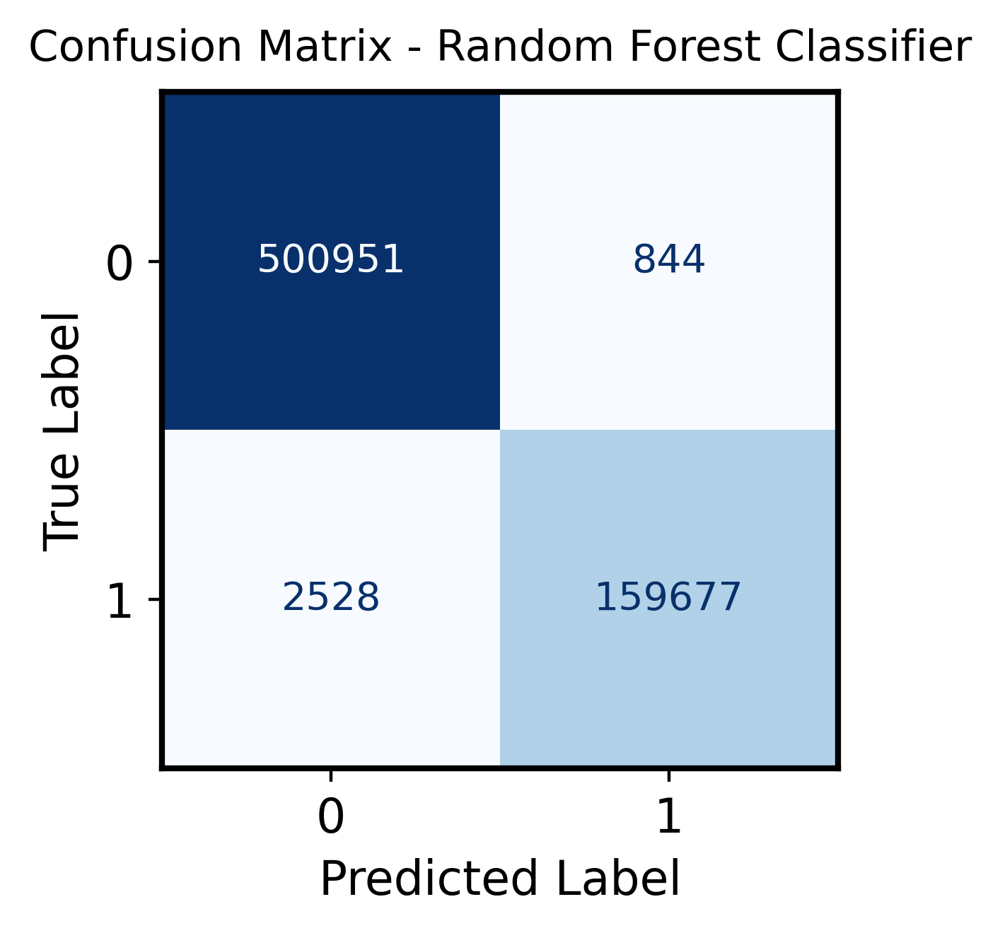

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
y_pred = RF_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test_b, y_pred)

# Compact figure for Word/Paper
fig, ax = plt.subplots(figsize=(3.4, 3.4), dpi=400)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(
    cmap='Blues',
    values_format='d',
    ax=ax,
    colorbar=False
)

# Make matrix values larger
for text in disp.text_.ravel():
    text.set_fontsize(10)

# Axis tick labels
ax.tick_params(axis='both', labelsize=12)

# Axis labels
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)

# Thick black border around entire matrix
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.5)

# Title
ax.set_title(
    'Confusion Matrix - Random Forest Classifier',
    fontsize=11,
    pad=8
)

plt.tight_layout()

# Save figure
plt.savefig(
    'confusion_matrix_rf.png',
    dpi=400,
    bbox_inches='tight',
    pad_inches=0.02
)

plt.show()

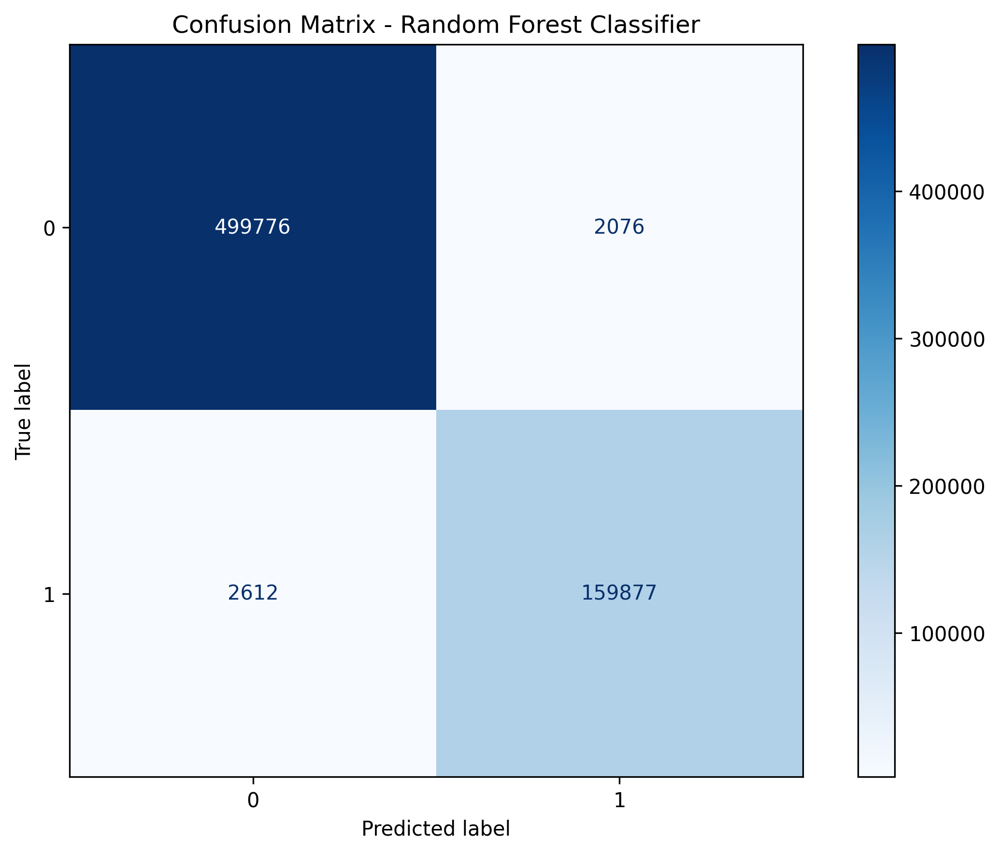

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict class labels
y_pred = RF_model.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(y_test_b, y_pred)

# Create high-resolution figure
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(ax=ax, cmap='Blues', values_format='d')

ax.set_title('Confusion Matrix - Random Forest Classifier')

plt.tight_layout()
plt.show()


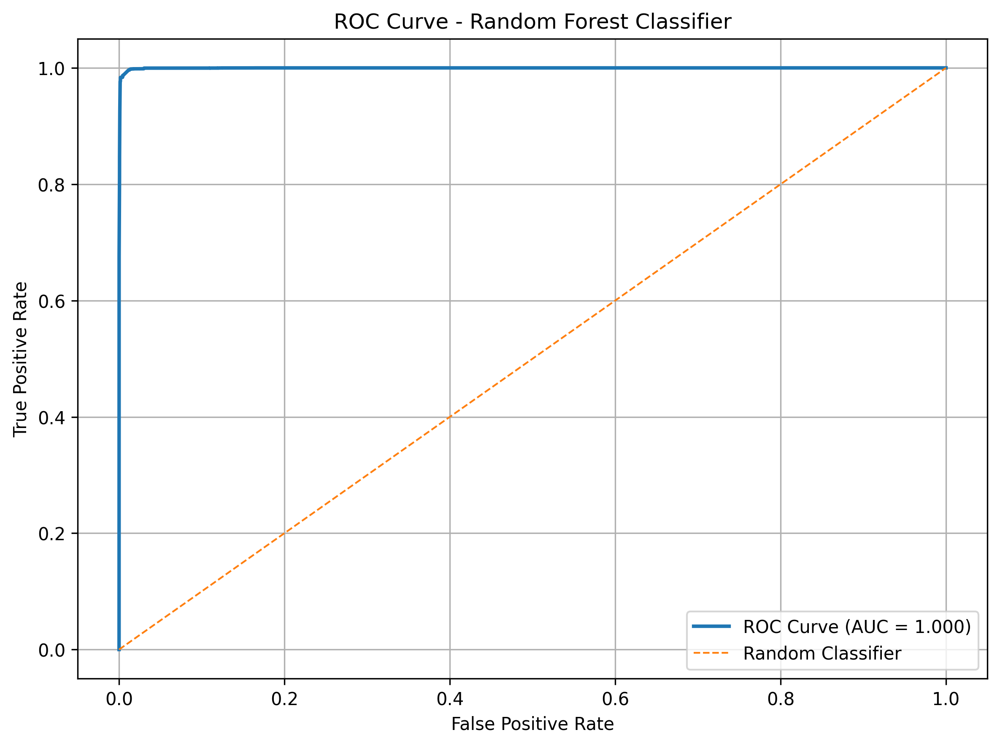

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Predict probabilities for the positive class (class = 1)
y_test_prob = RF_model.predict_proba(X_test)[:, 1]

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test_b, y_test_prob)

# Compute AUC
auc_score = roc_auc_score(y_test_b, y_test_prob)

# Create high-resolution figure
plt.figure(figsize=(8, 6), dpi=300)

plt.plot(fpr, tpr, linewidth=2,
         label=f'ROC Curve (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', linewidth=1,
         label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest Classifier')
plt.legend(loc='lower right')
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

# Build pipeline
logreg_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # ignores NaNs
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        random_state=42,
        max_iter=1000,
        solver='lbfgs'
    ))
])

# Train
logreg_pipeline.fit(X_train, y_train_b)

# Evaluate
def eval_metric(model, X_train, y_train_b, X_test, y_test_b):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)

    print("Test_Set")
    print(confusion_matrix(y_test_b, y_pred))
    print(classification_report(y_test_b, y_pred))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train_b, y_train_pred))
    print(classification_report(y_train_b, y_train_pred))

eval_metric(logreg_pipeline, X_train, y_train_b, X_test, y_test_b)


Test_Set
[[472845  28950]
 [ 54937 107268]]
              precision    recall  f1-score   support

           0       0.90      0.94      0.92    501795
           1       0.79      0.66      0.72    162205

    accuracy                           0.87    664000
   macro avg       0.84      0.80      0.82    664000
weighted avg       0.87      0.87      0.87    664000


Train_Set
[[1103249   67605]
 [ 127988  250489]]
              precision    recall  f1-score   support

           0       0.90      0.94      0.92   1170854
           1       0.79      0.66      0.72    378477

    accuracy                           0.87   1549331
   macro avg       0.84      0.80      0.82   1549331
weighted avg       0.87      0.87      0.87   1549331



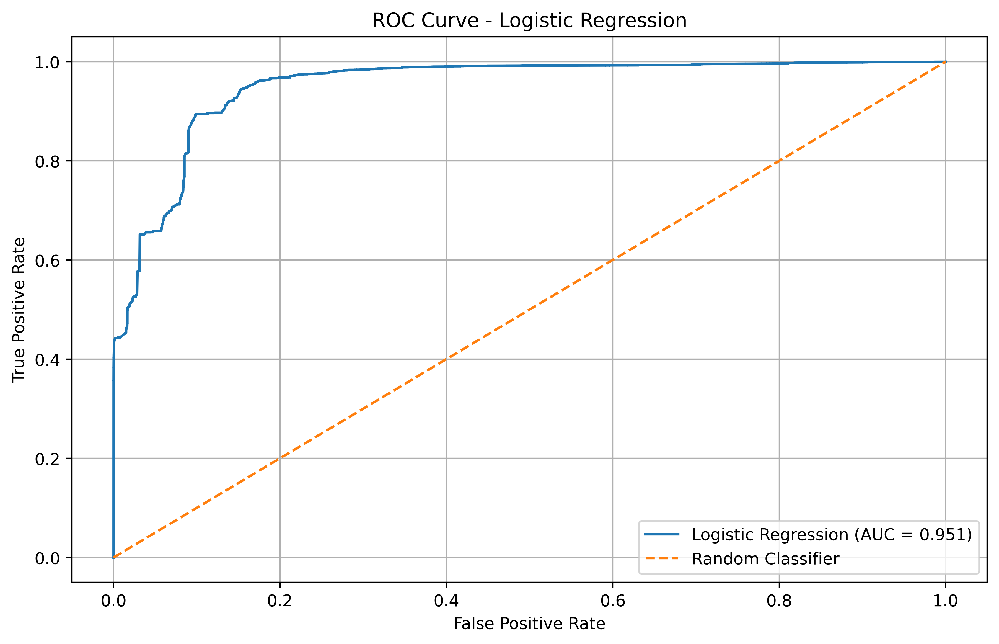

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Predict probabilities for positive class (1)
y_test_prob = logreg_pipeline.predict_proba(X_test)[:, 1]

# Compute ROC curve values
fpr, tpr, _ = roc_curve(y_test_b, y_test_prob)

# Compute AUC
auc_score = roc_auc_score(y_test_b, y_test_prob)

# Plot ROC curve
plt.figure(dpi=400)
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


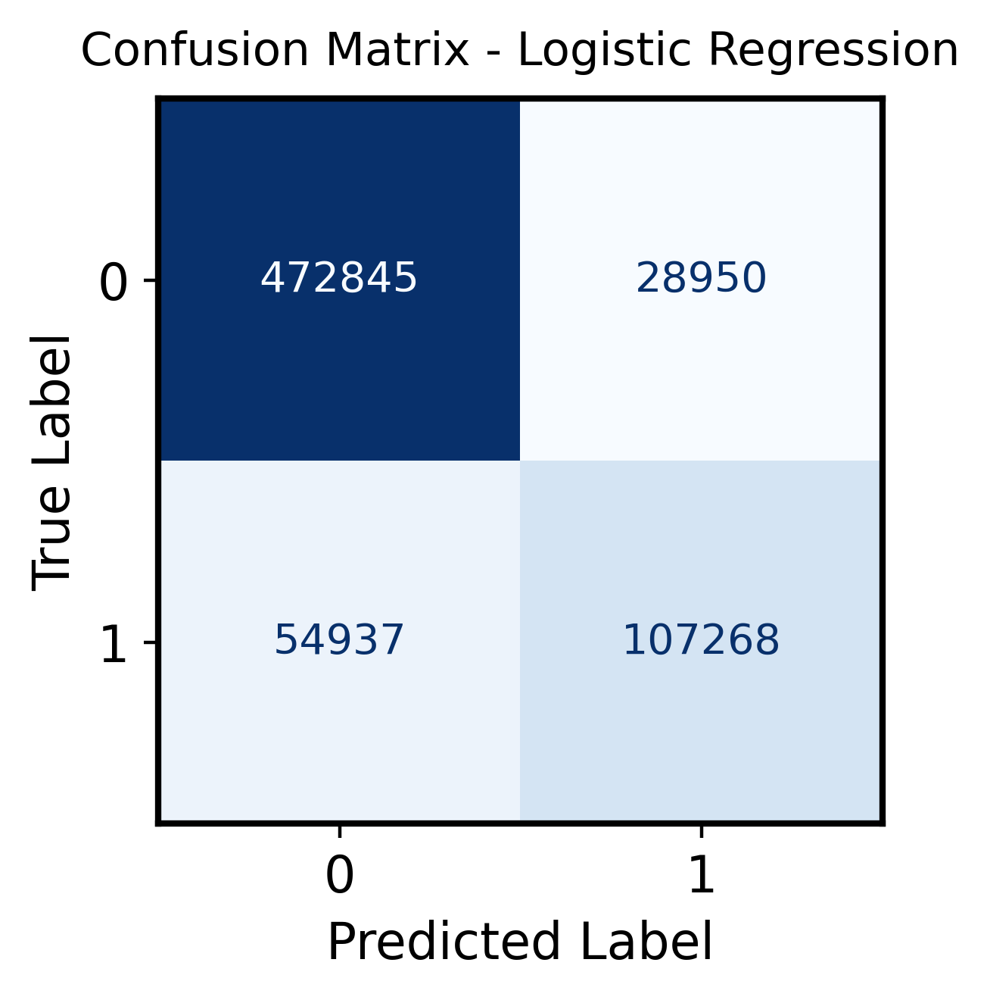

In [ ]:
y_pred = logreg_pipeline.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test_b, y_pred)

# Compact figure for Word/Paper
fig, ax = plt.subplots(figsize=(3.5, 3.4), dpi=400)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(
    cmap='Blues',
    values_format='d',
    ax=ax,
    colorbar=False
)

# Make matrix values larger
for text in disp.text_.ravel():
    text.set_fontsize(10)

# Axis tick labels
ax.tick_params(axis='both', labelsize=12)

# Axis labels
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)

# Single black border around the matrix
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.5)

# Title
ax.set_title(
    'Confusion Matrix - Logistic Regression',
    fontsize=11,
    pad=8
)

plt.tight_layout()

# Save figure
plt.savefig(
    'confusion_matrix_logreg.png',
    dpi=400,
    bbox_inches='tight',
    pad_inches=0.02
)

plt.show()

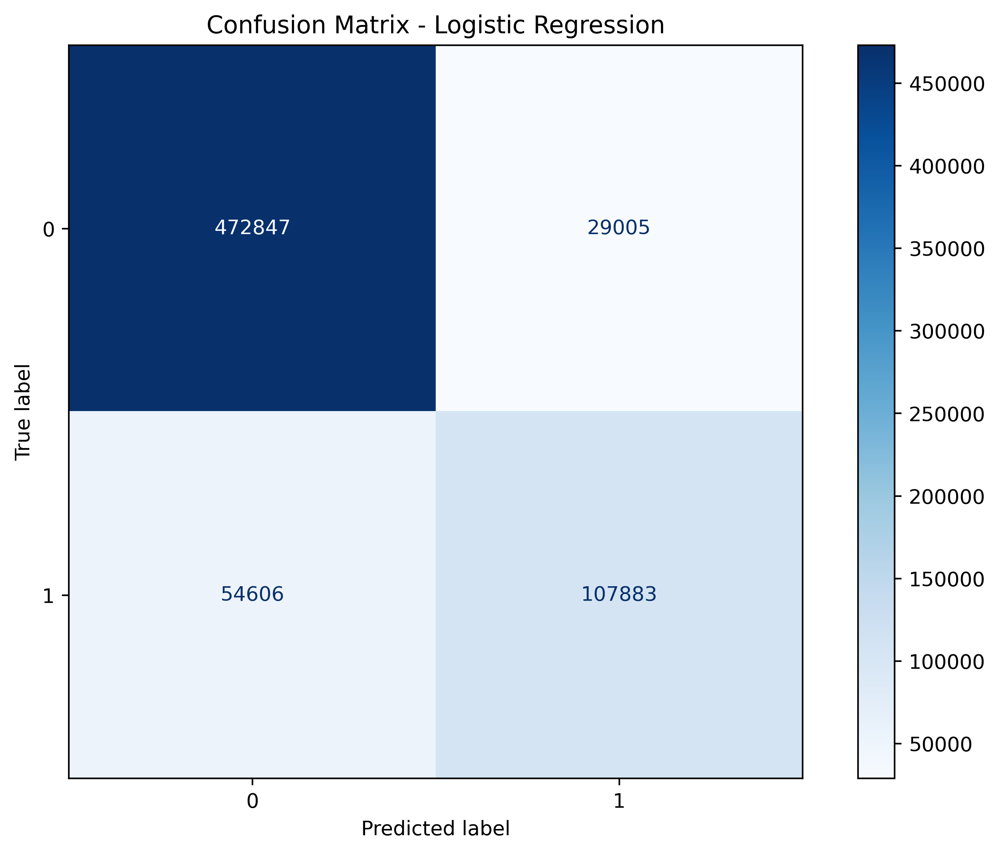

In [ ]:
y_pred = logreg_pipeline.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(y_test_b, y_pred)

# Create high-resolution figure
fig, ax = plt.subplots(figsize=(8, 6), dpi=400)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(ax=ax, cmap='Blues', values_format='d')

ax.set_title('Confusion Matrix - Logistic Regression')

plt.tight_layout()
plt.show()